In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, log_loss, roc_auc_score, roc_curve, auc)
import lightgbm as lgb
from IPython.display import Image, display

In [2]:
df = pd.read_csv("C:/MyProjects/BIA_assign/BIA_final/project_data.csv")
df.head()
df = df.drop('id', axis=1)

In [3]:
df.describe()

,Age,Annual_Income,Previously_Insured
count,508146.000000,5.081460e+05,508146.000000
mean,38.808413,9.166336e+04,0.458667
std,15.500179,5.143972e+04,0.498289
min,20.000000,7.890000e+03,0.000000
25%,25.000000,7.314300e+04,0.000000
50%,36.000000,9.498300e+04,0.000000
75%,49.000000,1.182112e+05,1.000000
max,85.000000,1.620495e+06,1.000000


In [4]:
print(df["Vehicle_Type"].value_counts())
print(df["Location_Type"].value_counts())
print(df["Region_Code"].value_counts())

Vehicle_Type
Normal Car    237055
SUV           207023
Luxury SUV     38892
Luxury Car     25176
Name: count, dtype: int64
Location_Type
Urban       236515
Suburban    145521
Rural       126110
Name: count, dtype: int64
Region_Code
NE    187733
W     143897
S      88299
MW     88217
Name: count, dtype: int64


In [5]:
print(df.groupby(["Location_Type"])["Annual_Income"].agg(["mean", "sum", "count"]))
print(df.groupby(["Policy"])["Annual_Income"].agg(["mean", "sum", "count"]).sort_values(by="mean"))

                       mean          sum   count
Location_Type                                   
Rural          81765.974744  10311507075  126110
Suburban       86873.206362  12641875863  145521
Urban          99887.898641  23624986347  236515
                            mean         sum  count
Policy                                             
Basic               11702.512926  1103160786  94267
Silver Tier II      79338.646661  7187288001  90590
Silver Tier I       87555.277324  7282585302  83177
Gold Tier II       103352.481485  7128427353  68972
Gold Tier I        114995.075787  7193746956  62557
Platinium Tier II  141983.076856  7772011644  54739
Platinium Tier I   165499.391631  8911149243  53844


## Model Building

In [6]:
# Nominal categorical variable
df = pd.get_dummies(
    df,
    columns=['Gender', 'Region_Code', 'Location_Type', 'Vehicle_Type'],
    drop_first=False
)

In [7]:
df.head(1)

,Age,Education,Annual_Income,Previously_Insured,Vehicle_Age,Vehicle_Damage,Policy,Gender_Female,Gender_Male,Region_Code_MW,Region_Code_NE,Region_Code_S,Region_Code_W,Location_Type_Rural,Location_Type_Suburban,Location_Type_Urban,Vehicle_Type_Luxury Car,Vehicle_Type_Luxury SUV,Vehicle_Type_Normal Car,Vehicle_Type_SUV
0,44,Bachelors,121362,0,> 20 Years,Yes,Platinium Tier II,False,True,False,True,False,False,False,False,True,False,False,True,False


In [8]:
# ordinal categorical variable
df['Education'] = df['Education'].map({'High School or Below': 0,'College': 1,'Bachelors': 2,'Masters': 3,'Doctor': 4})
df['Vehicle_Age'] = df['Vehicle_Age'].map({'< 10 Years': 0,'10-20 Years': 1,'> 20 Years': 2})
df['Vehicle_Damage'] = df['Vehicle_Damage'].map({'No': 0,'Yes': 1})
scaler = StandardScaler()
df['Annual_Income'] = scaler.fit_transform(df[['Annual_Income']])
df['Policy'] = df['Policy'].map({'Basic': 0,'Silver Tier I': 1,'Silver Tier II': 2,'Gold Tier I': 3,'Gold Tier II': 4,'Platinium Tier I': 5,'Platinium Tier II': 6})
df = df.astype({col: int for col in df.select_dtypes(include='bool').columns})

In [9]:
df.head(1)

,Age,Education,Annual_Income,Previously_Insured,Vehicle_Age,Vehicle_Damage,Policy,Gender_Female,Gender_Male,Region_Code_MW,Region_Code_NE,Region_Code_S,Region_Code_W,Location_Type_Rural,Location_Type_Suburban,Location_Type_Urban,Vehicle_Type_Luxury Car,Vehicle_Type_Luxury SUV,Vehicle_Type_Normal Car,Vehicle_Type_SUV
0,44,2,0.577349,0,2,1,6,0,1,0,1,0,0,0,0,1,0,0,1,0


In [10]:
X = df.drop('Policy', axis=1)
y = df['Policy']

In [11]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_eval, y_train, y_eval = train_test_split(X_temp,y_temp,test_size=0.2,random_state=42,stratify=y_temp)

print("Training:", X_train.shape)
print("Evaluation:", X_eval.shape)
print("Test:", X_test.shape)

Training: (345539, 19)
Evaluation: (86385, 19)
Test: (76222, 19)


In [12]:
model = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42, eval_metric='mlogloss')
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_eval, y_eval)],verbose=False)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

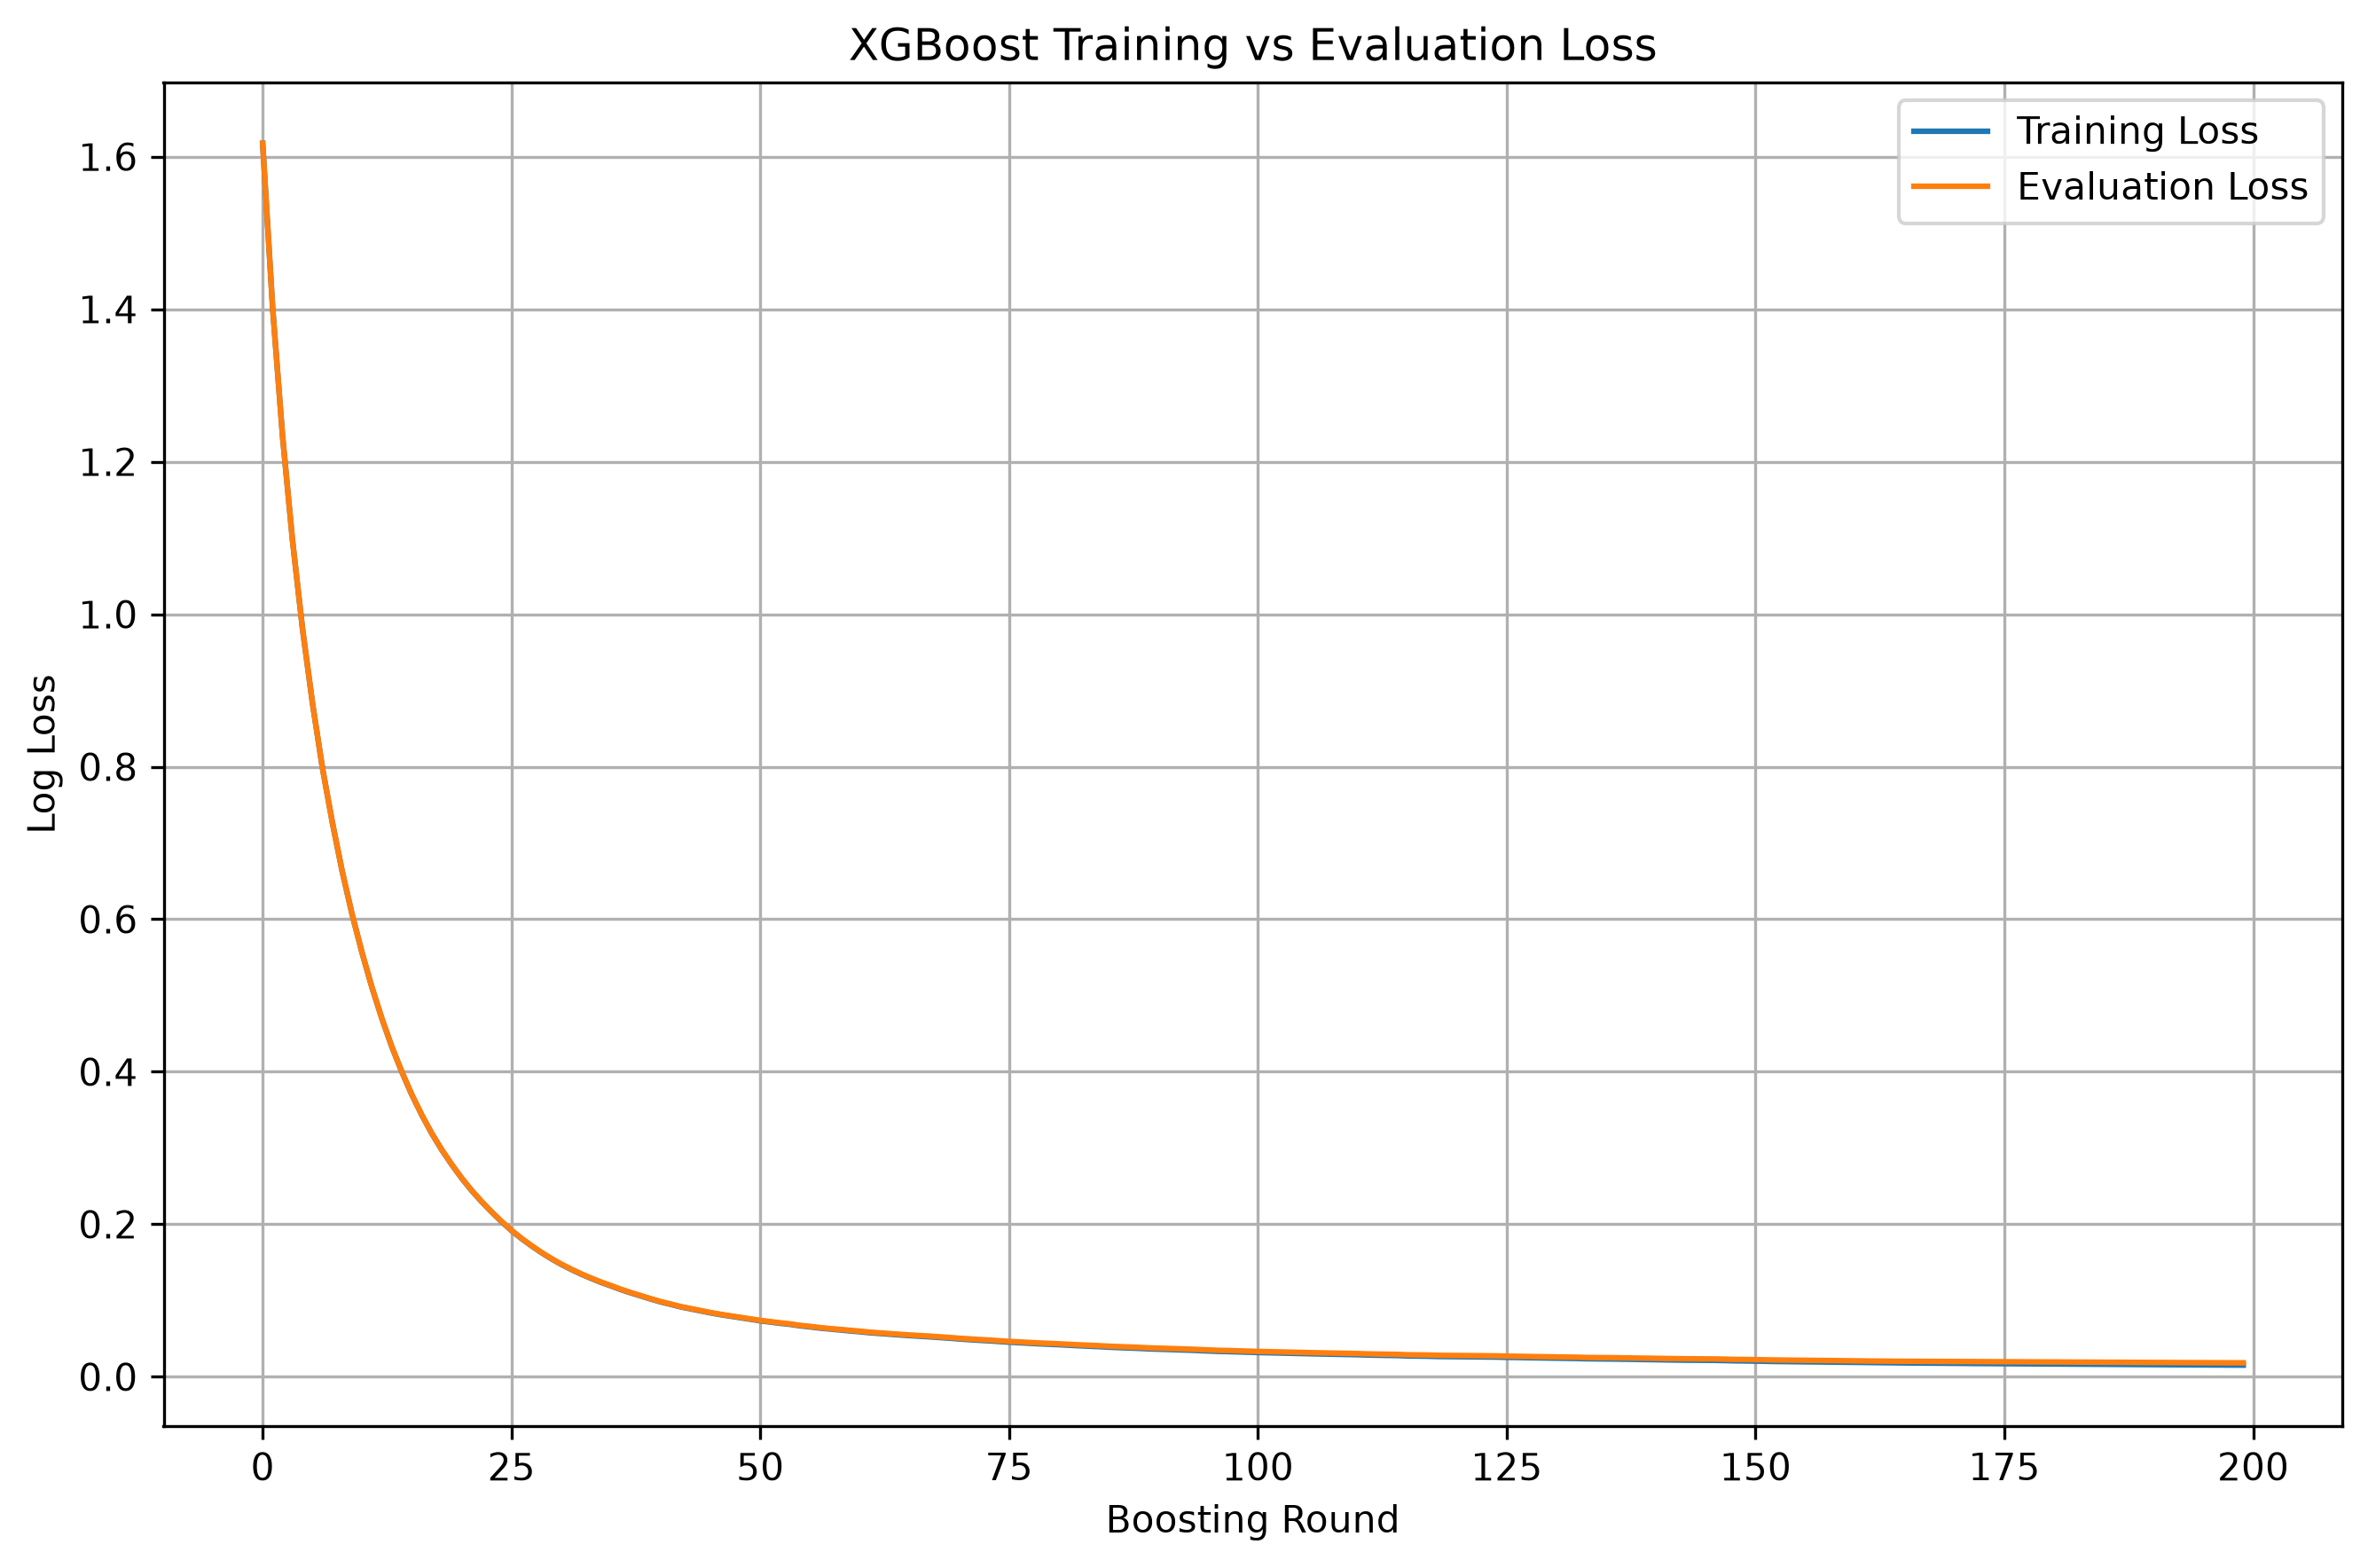

In [13]:
results = model.evals_result()

train_loss = results['validation_0']['mlogloss']
eval_loss = results['validation_1']['mlogloss']

plt.figure(figsize=(9, 6))

plt.plot(train_loss, label='Training Loss')
plt.plot(eval_loss, label='Evaluation Loss')

plt.xlabel('Boosting Round')
plt.ylabel('Log Loss')
plt.title('XGBoost Training vs Evaluation Loss')

plt.legend()
plt.grid(True)

plt.tight_layout()

# Save the figure
plt.savefig('xgboost_loss_curve.png', dpi=300, bbox_inches='tight')

# Display it
from IPython.display import Image, display
display(Image(filename='xgboost_loss_curve.png'))

## prediction

In [14]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

policy_names = ['Basic', 'Silver Tier I', 'Silver Tier II', 'Gold Tier I', 'Gold Tier II', 'Platinium Tier I', 'Platinium Tier II']
print(classification_report(y_test, y_pred, target_names=policy_names))

                   precision    recall  f1-score   support

            Basic       1.00      0.99      1.00     14140
    Silver Tier I       0.99      0.99      0.99     12477
   Silver Tier II       0.99      0.99      0.99     13588
      Gold Tier I       0.99      0.98      0.99      9383
     Gold Tier II       0.99      0.99      0.99     10346
 Platinium Tier I       1.00      1.00      1.00      8077
Platinium Tier II       0.99      1.00      0.99      8211

         accuracy                           0.99     76222
        macro avg       0.99      0.99      0.99     76222
     weighted avg       0.99      0.99      0.99     76222



# ROC

In [15]:
y_test_binary = label_binarize(y_test, classes=[0, 1, 2, 3, 4, 5, 6])
roc_auc = roc_auc_score( y_test_binary, y_prob, multi_class='ovr', average='weighted')
print("\nWeighted Multiclass ROC-AUC:", roc_auc)


Weighted Multiclass ROC-AUC: 0.9999523711744706


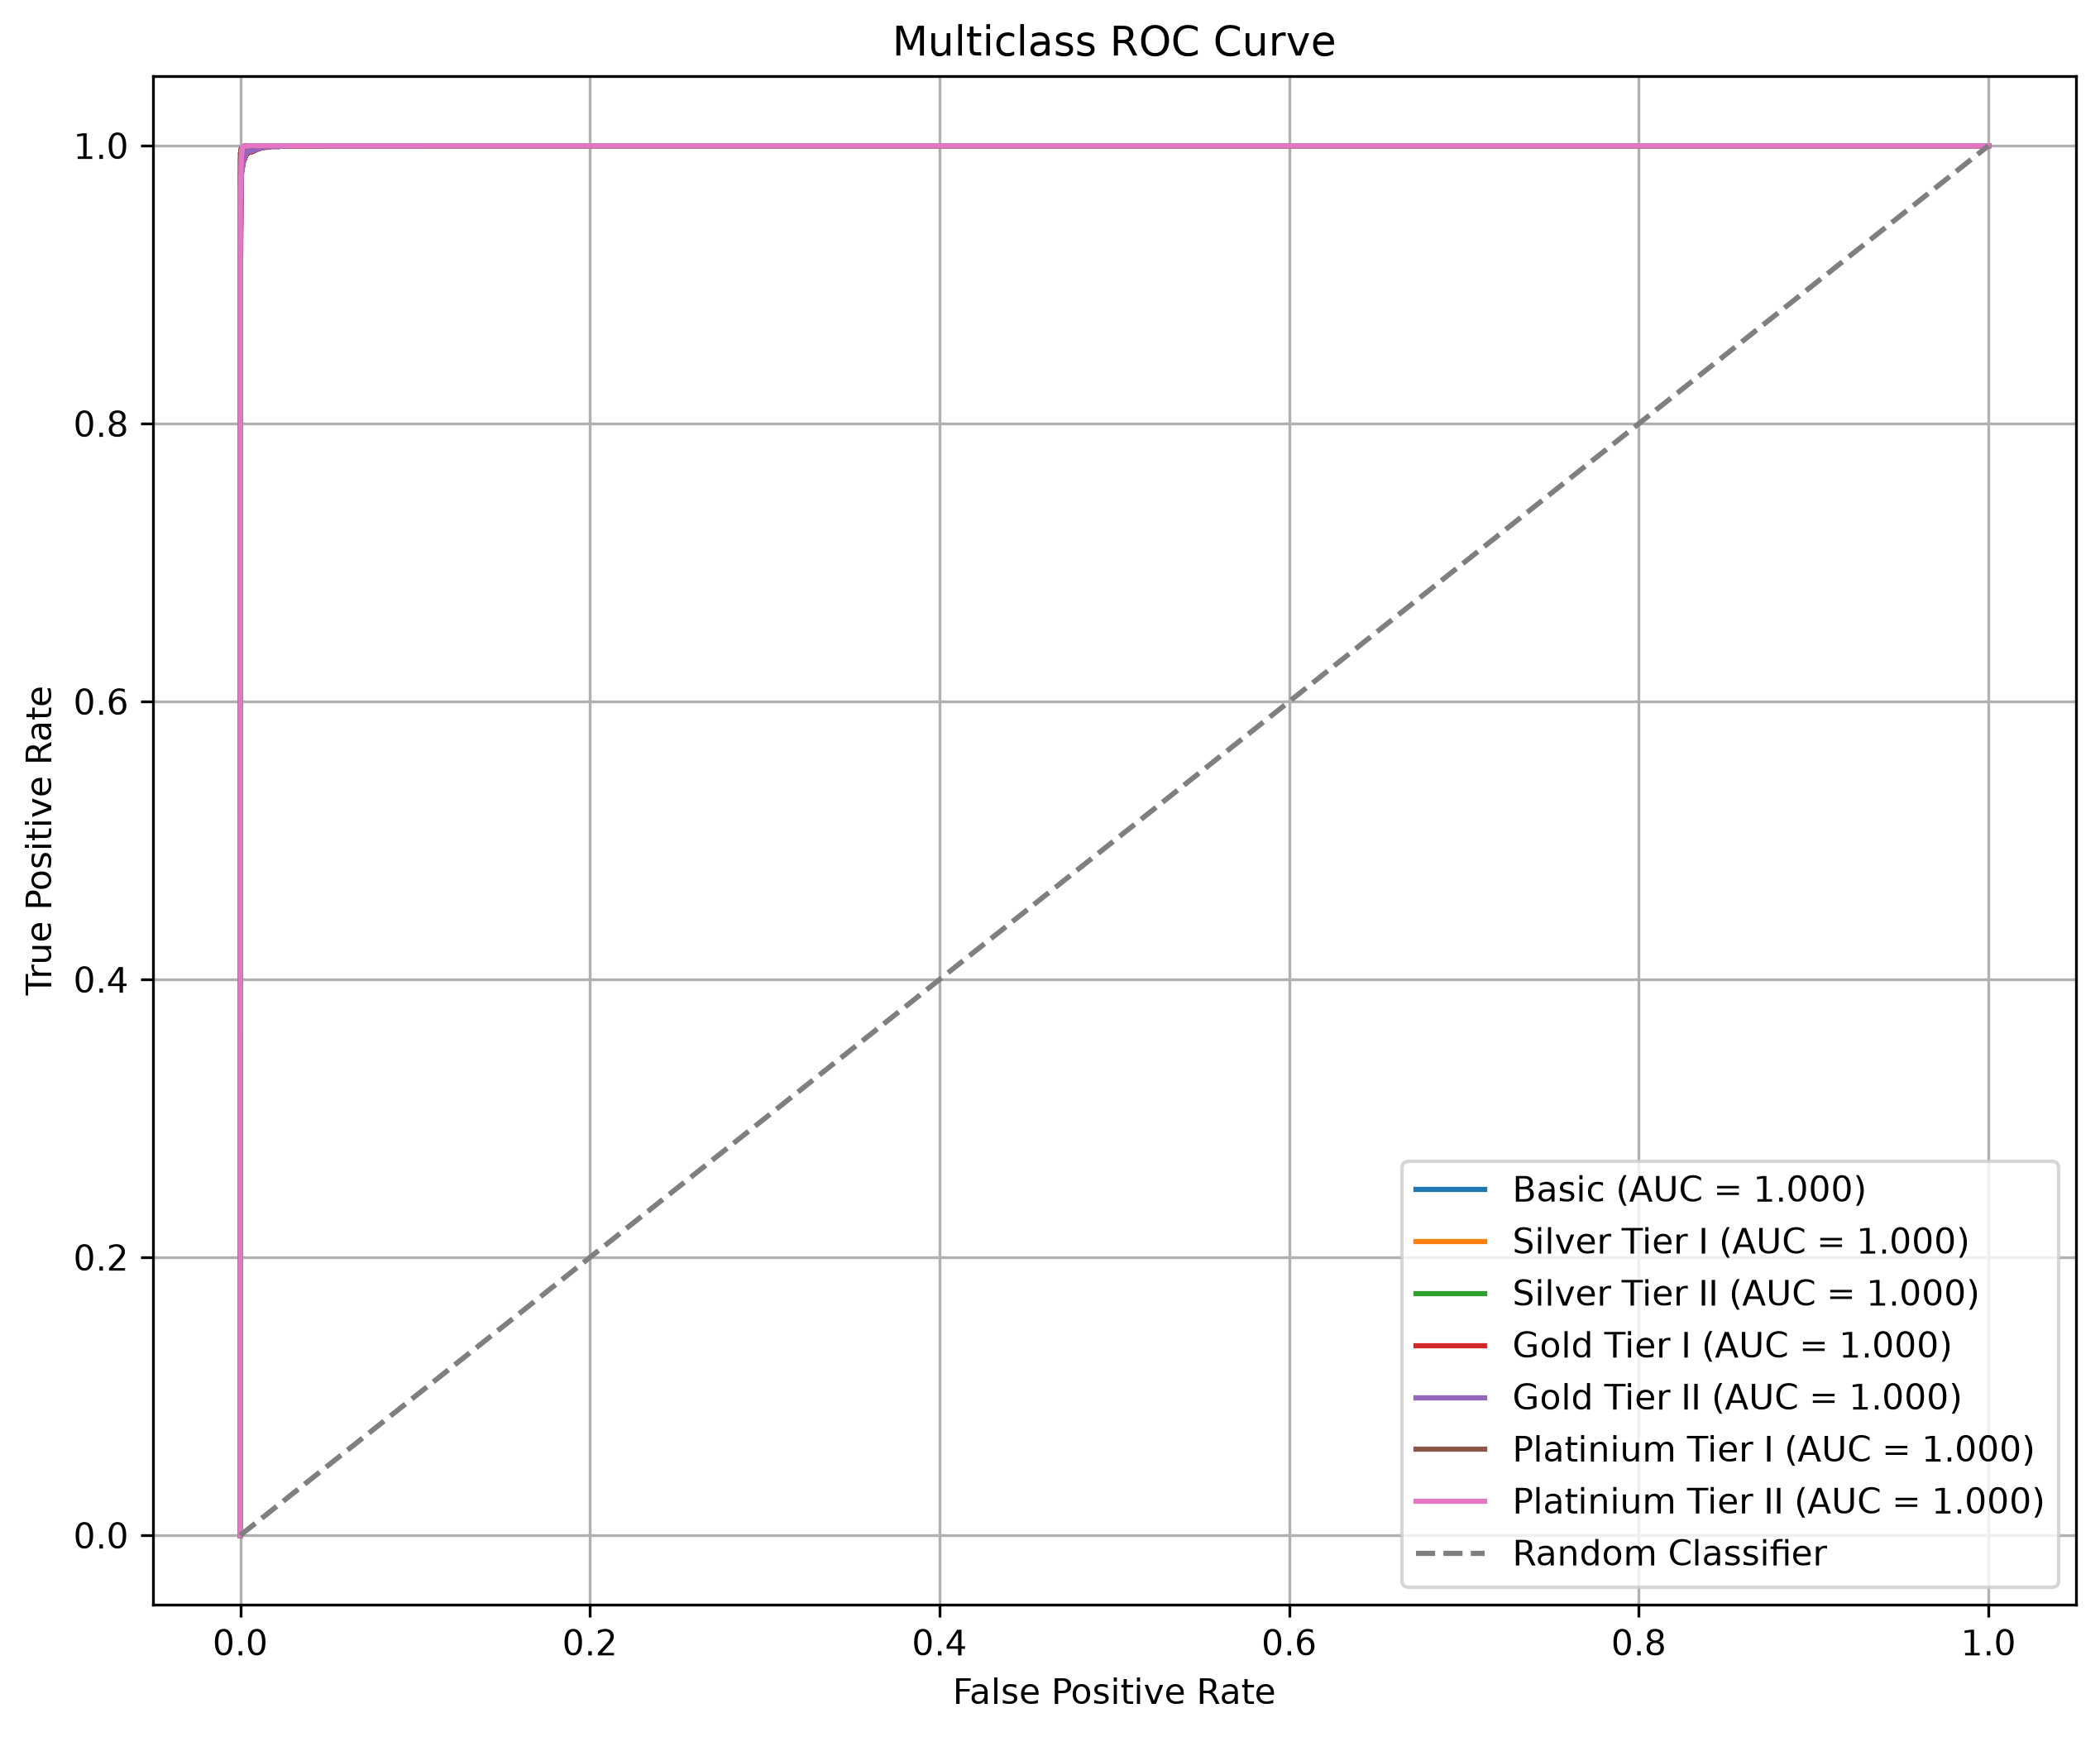

In [16]:
plt.figure(figsize=(10, 8))

for i in range(7):
    fpr, tpr, thresholds = roc_curve(y_test_binary[:, i],y_prob[:, i])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{policy_names[i]} (AUC = {class_auc:.3f})')

# Random classifier
plt.plot( [0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)

plt.savefig(
    'multiclass_roc_curve.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

display(Image(filename='multiclass_roc_curve.png'))

# feature importance

In [17]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)
print("\nFeature Importance:")
print(importance)


Feature Importance:
                    Feature  Importance
2             Annual_Income    0.352940
4               Vehicle_Age    0.152602
17  Vehicle_Type_Normal Car    0.095104
5            Vehicle_Damage    0.073347
1                 Education    0.069421
9            Region_Code_NE    0.069250
6             Gender_Female    0.046248
14      Location_Type_Urban    0.024131
10            Region_Code_S    0.022751
13   Location_Type_Suburban    0.022056
12      Location_Type_Rural    0.018512
8            Region_Code_MW    0.017703
11            Region_Code_W    0.015265
3        Previously_Insured    0.015027
0                       Age    0.003020
15  Vehicle_Type_Luxury Car    0.001087
16  Vehicle_Type_Luxury SUV    0.000866
18         Vehicle_Type_SUV    0.000672
7               Gender_Male    0.000000


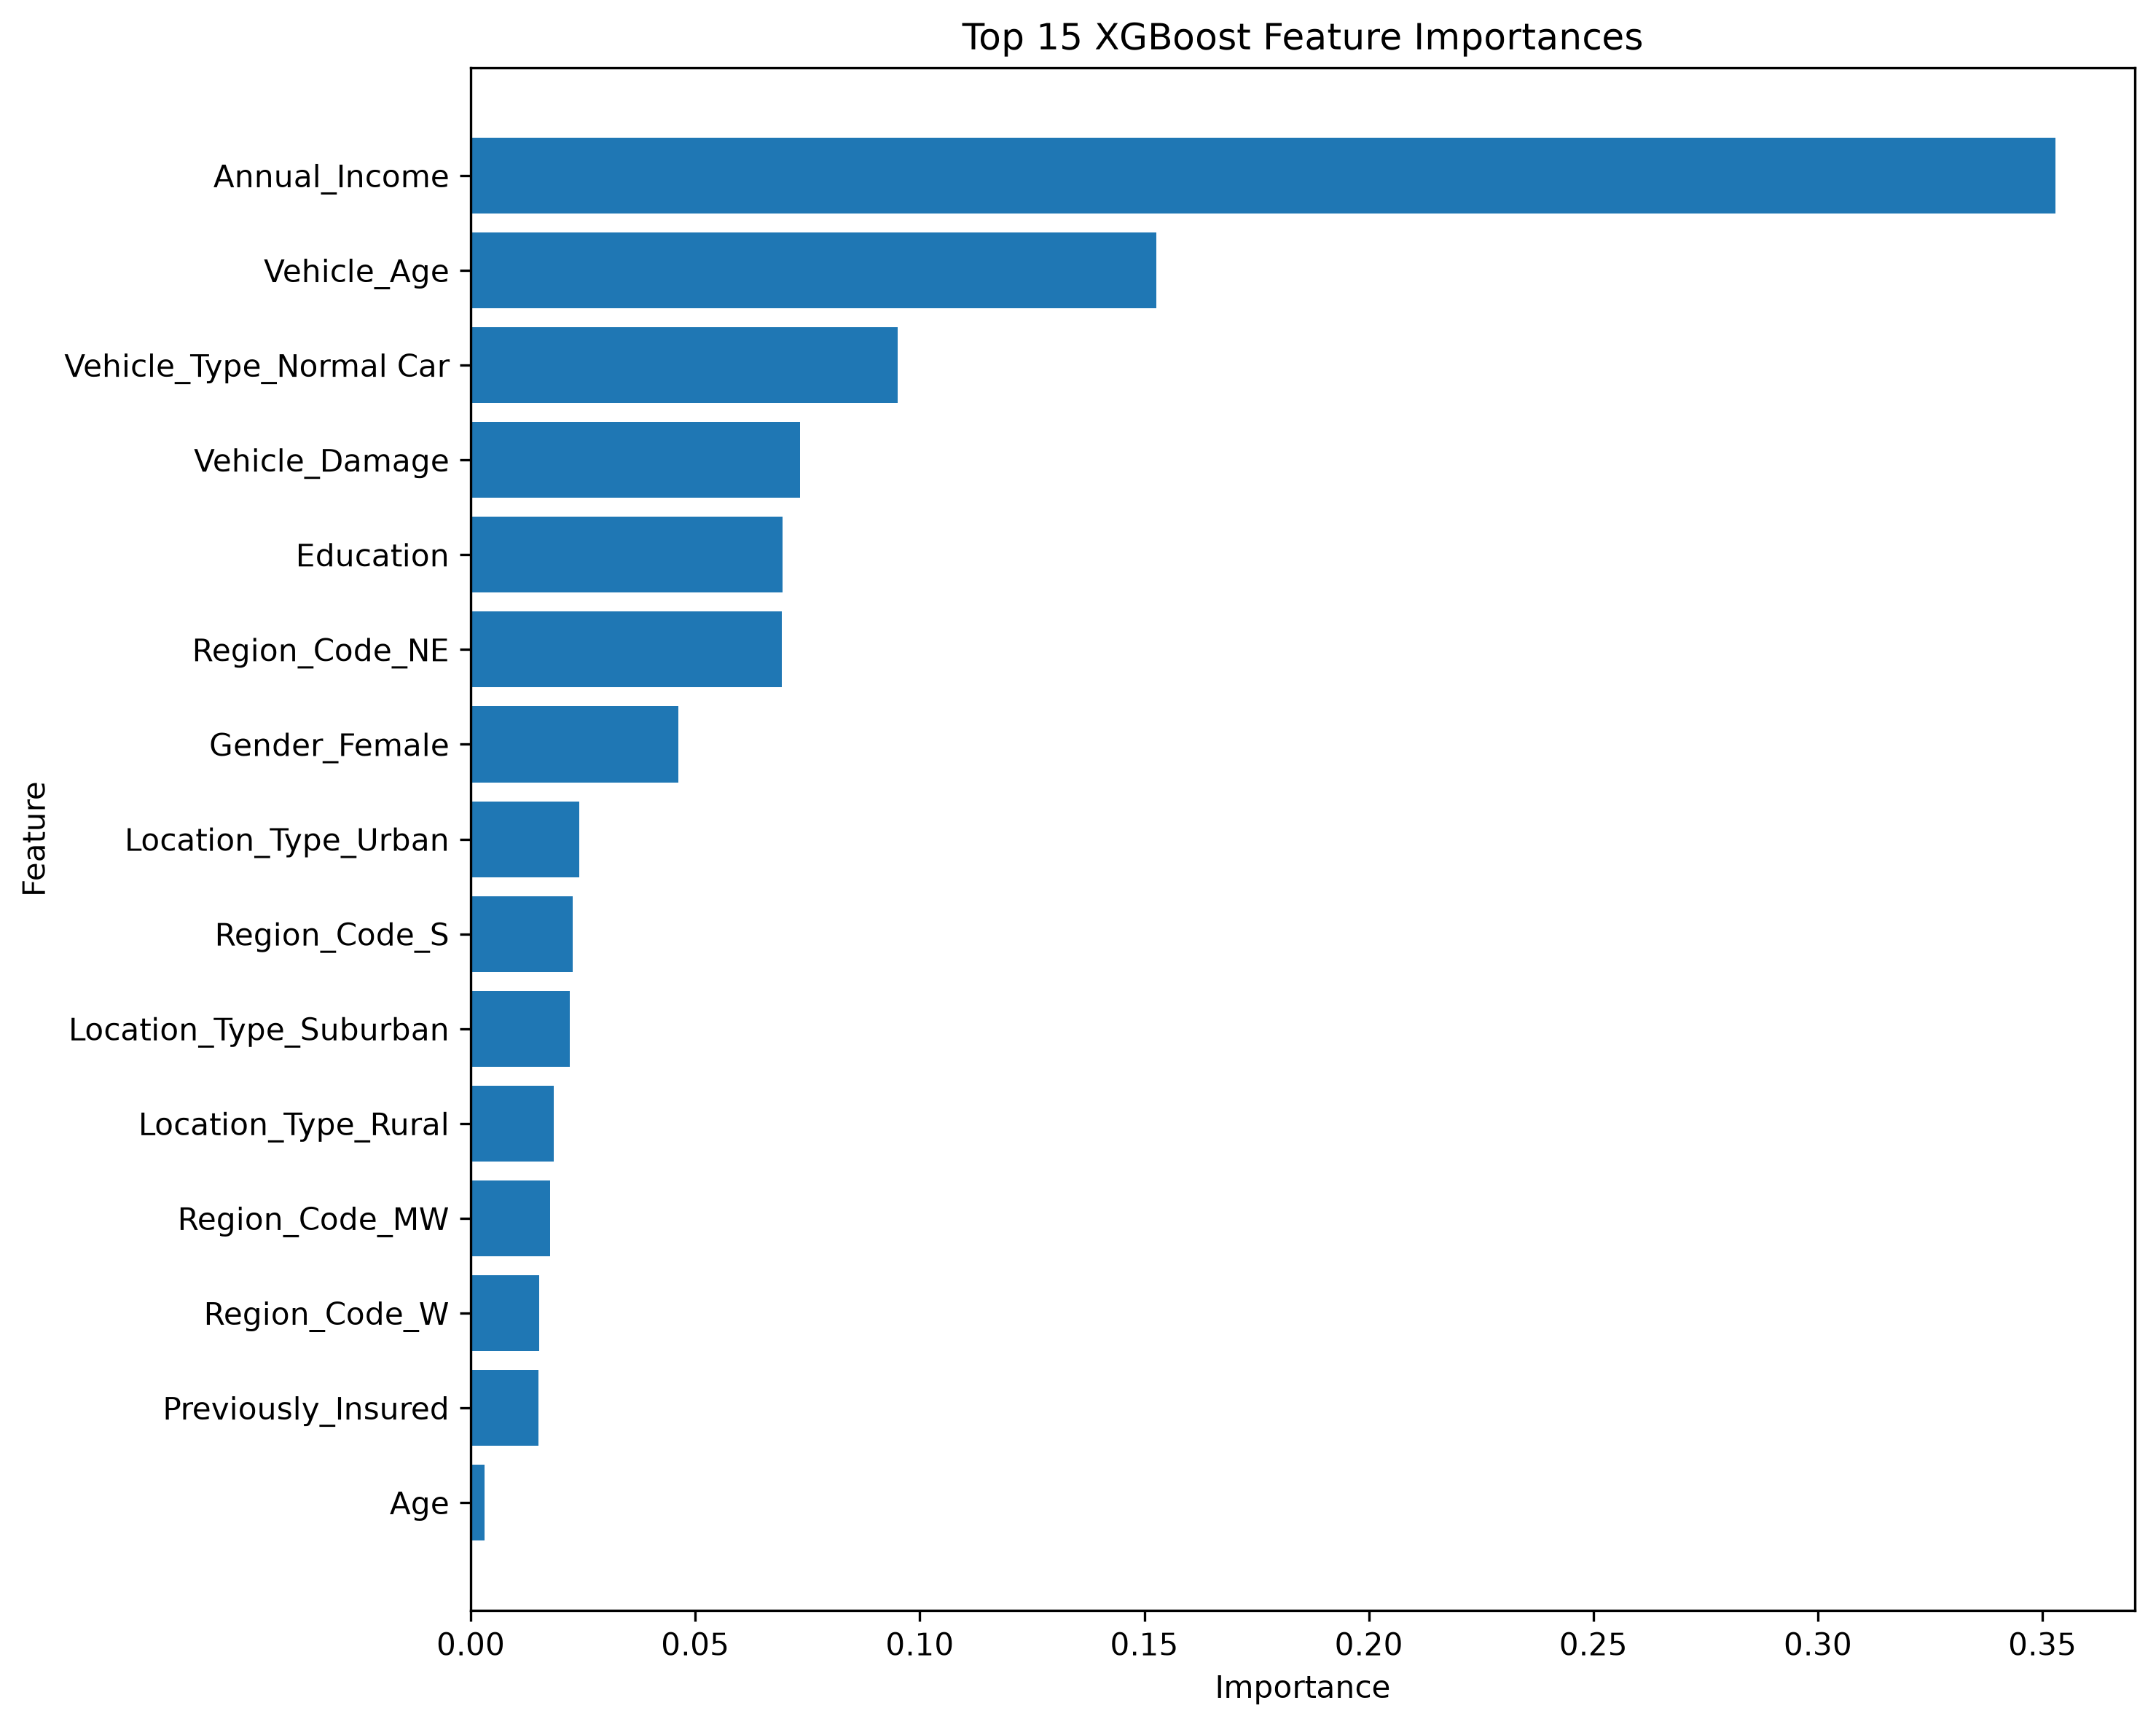

In [18]:
plt.figure(figsize=(10, 8))

top_features = importance.head(15)
plt.barh( top_features['Feature'], top_features['Importance'])

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 15 XGBoost Feature Importances')

plt.gca().invert_yaxis()
plt.tight_layout()

# Save the graph
plt.savefig( 'top_15_feature_importances.png', dpi=300, bbox_inches='tight')
plt.close()
display(Image(filename='top_15_feature_importances.png'))

# decision Tree model for comparison

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

depths = [3, 5, 7, 10, 15]

eval_results = []
for depth in depths:
    dt_model = DecisionTreeClassifier(max_depth=depth, random_state=42)

    dt_model.fit(X_train, y_train)

    y_eval_pred = dt_model.predict(X_eval)
    eval_accuracy = accuracy_score( y_eval, y_eval_pred)

    eval_results.append({ 'Max Depth': depth, 'Evaluation Accuracy': eval_accuracy})

dt_eval_results = pd.DataFrame(eval_results)

print(dt_eval_results)

   Max Depth  Evaluation Accuracy
0          3             0.655542
1          5             0.837970
2          7             0.955096
3         10             0.991387
4         15             0.999294


In [20]:
best_depth = dt_eval_results.loc[
    dt_eval_results['Evaluation Accuracy'].idxmax(),'Max Depth']

print("Best Max Depth:", best_depth)

Best Max Depth: 15


In [21]:
dt_model = DecisionTreeClassifier( max_depth=best_depth, random_state=42)

dt_model.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(15)
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number of

In [22]:
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)

print("Decision Tree Classification Report:\n")

print(classification_report( y_test, y_pred_dt, target_names=policy_names))

Decision Tree Classification Report:

                   precision    recall  f1-score   support

            Basic       1.00      1.00      1.00     14140
    Silver Tier I       1.00      1.00      1.00     12477
   Silver Tier II       1.00      1.00      1.00     13588
      Gold Tier I       1.00      1.00      1.00      9383
     Gold Tier II       1.00      1.00      1.00     10346
 Platinium Tier I       1.00      1.00      1.00      8077
Platinium Tier II       1.00      1.00      1.00      8211

         accuracy                           1.00     76222
        macro avg       1.00      1.00      1.00     76222
     weighted avg       1.00      1.00      1.00     76222



In [23]:
from sklearn.metrics import roc_auc_score

dt_roc_auc = roc_auc_score(
    y_test_binary,
    y_prob_dt,
    multi_class='ovr',
    average='weighted'
)

print("Decision Tree Weighted ROC-AUC:", dt_roc_auc)

Decision Tree Weighted ROC-AUC: 0.9995074321997316


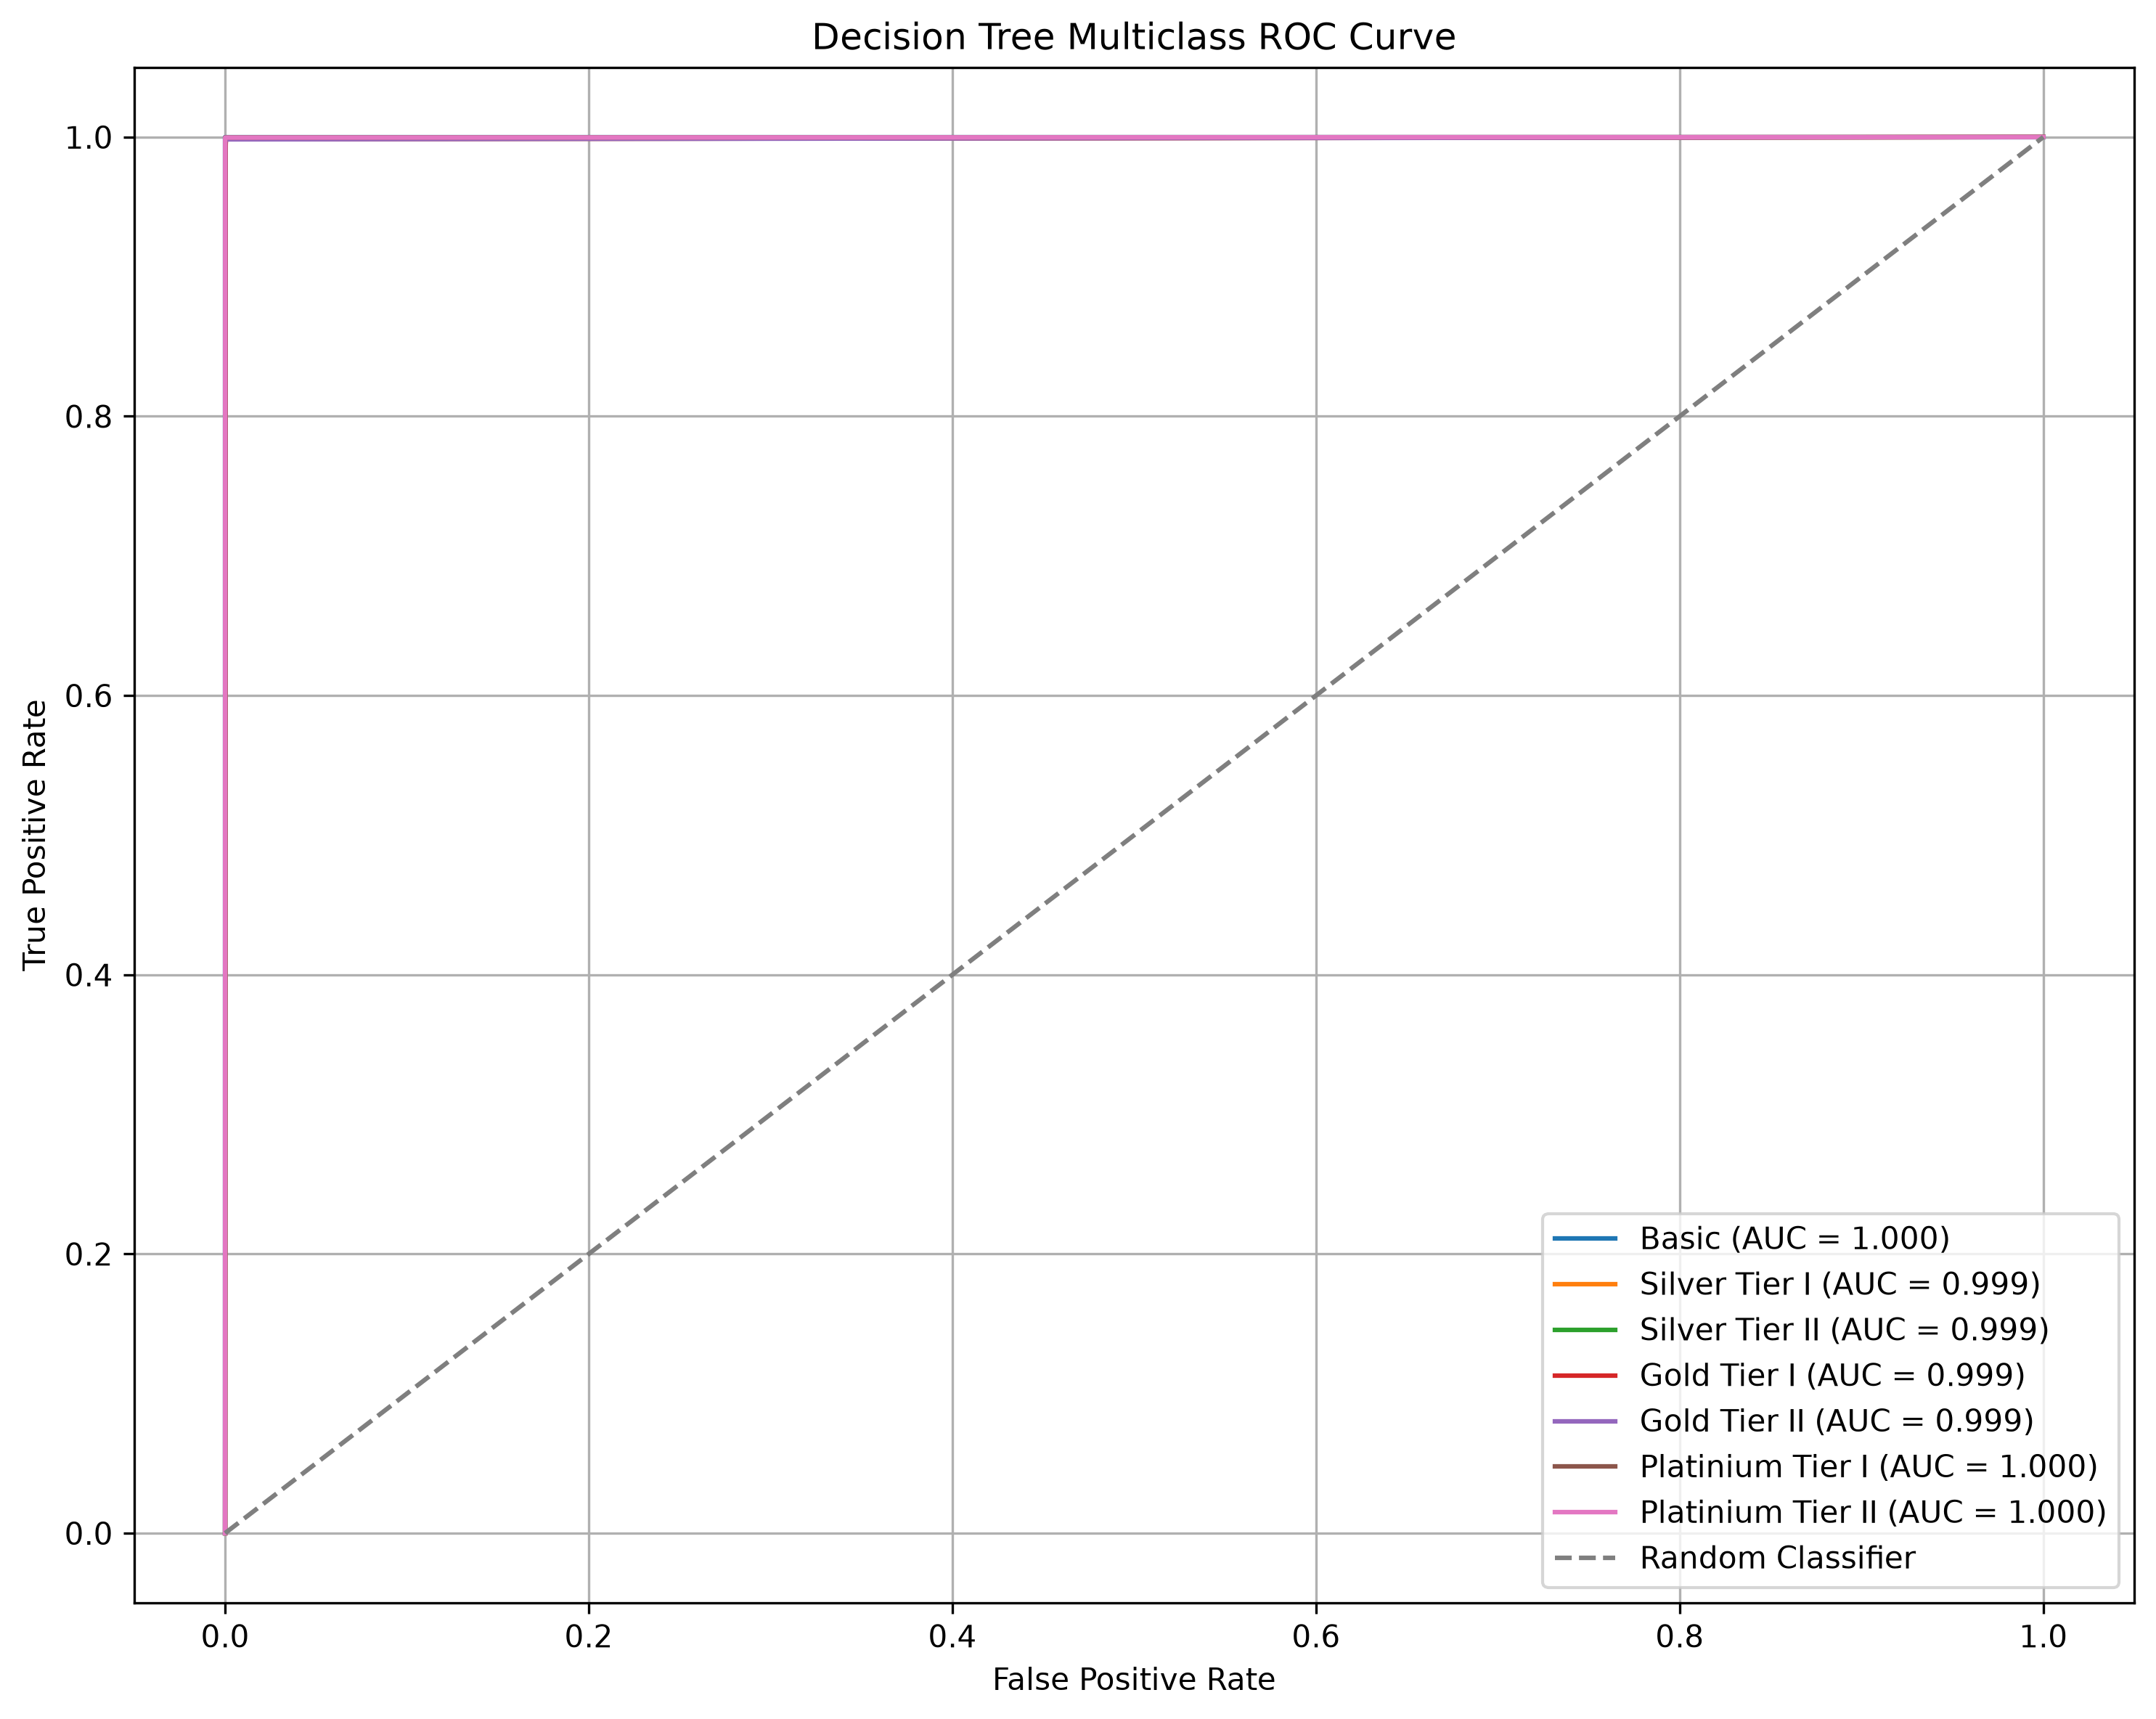

In [24]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

for i in range(7):
    fpr, tpr, thresholds = roc_curve( y_test_binary[:, i], y_prob_dt[:, i])
    class_auc = auc( fpr, tpr)
    plt.plot( fpr, tpr, label=f'{policy_names[i]} (AUC = {class_auc:.3f})')

# Random classifier
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Decision Tree Multiclass ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()

plt.savefig('decision_tree_roc_curve.png', dpi=300, bbox_inches='tight')
plt.close()
display(Image(filename='decision_tree_roc_curve.png'))

In [26]:
dt_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': dt_model.feature_importances_
})

# Sort from highest to lowest
dt_importance = dt_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
top_dt_features = dt_importance.head(15)

print(top_dt_features)

                    Feature  Importance
2             Annual_Income    0.658733
4               Vehicle_Age    0.131189
1                 Education    0.090525
18         Vehicle_Type_SUV    0.034202
9            Region_Code_NE    0.017677
5            Vehicle_Damage    0.013516
12      Location_Type_Rural    0.009447
8            Region_Code_MW    0.008573
17  Vehicle_Type_Normal Car    0.007186
14      Location_Type_Urban    0.006912
6             Gender_Female    0.006035
13   Location_Type_Suburban    0.004473
0                       Age    0.003574
10            Region_Code_S    0.003573
3        Previously_Insured    0.003024


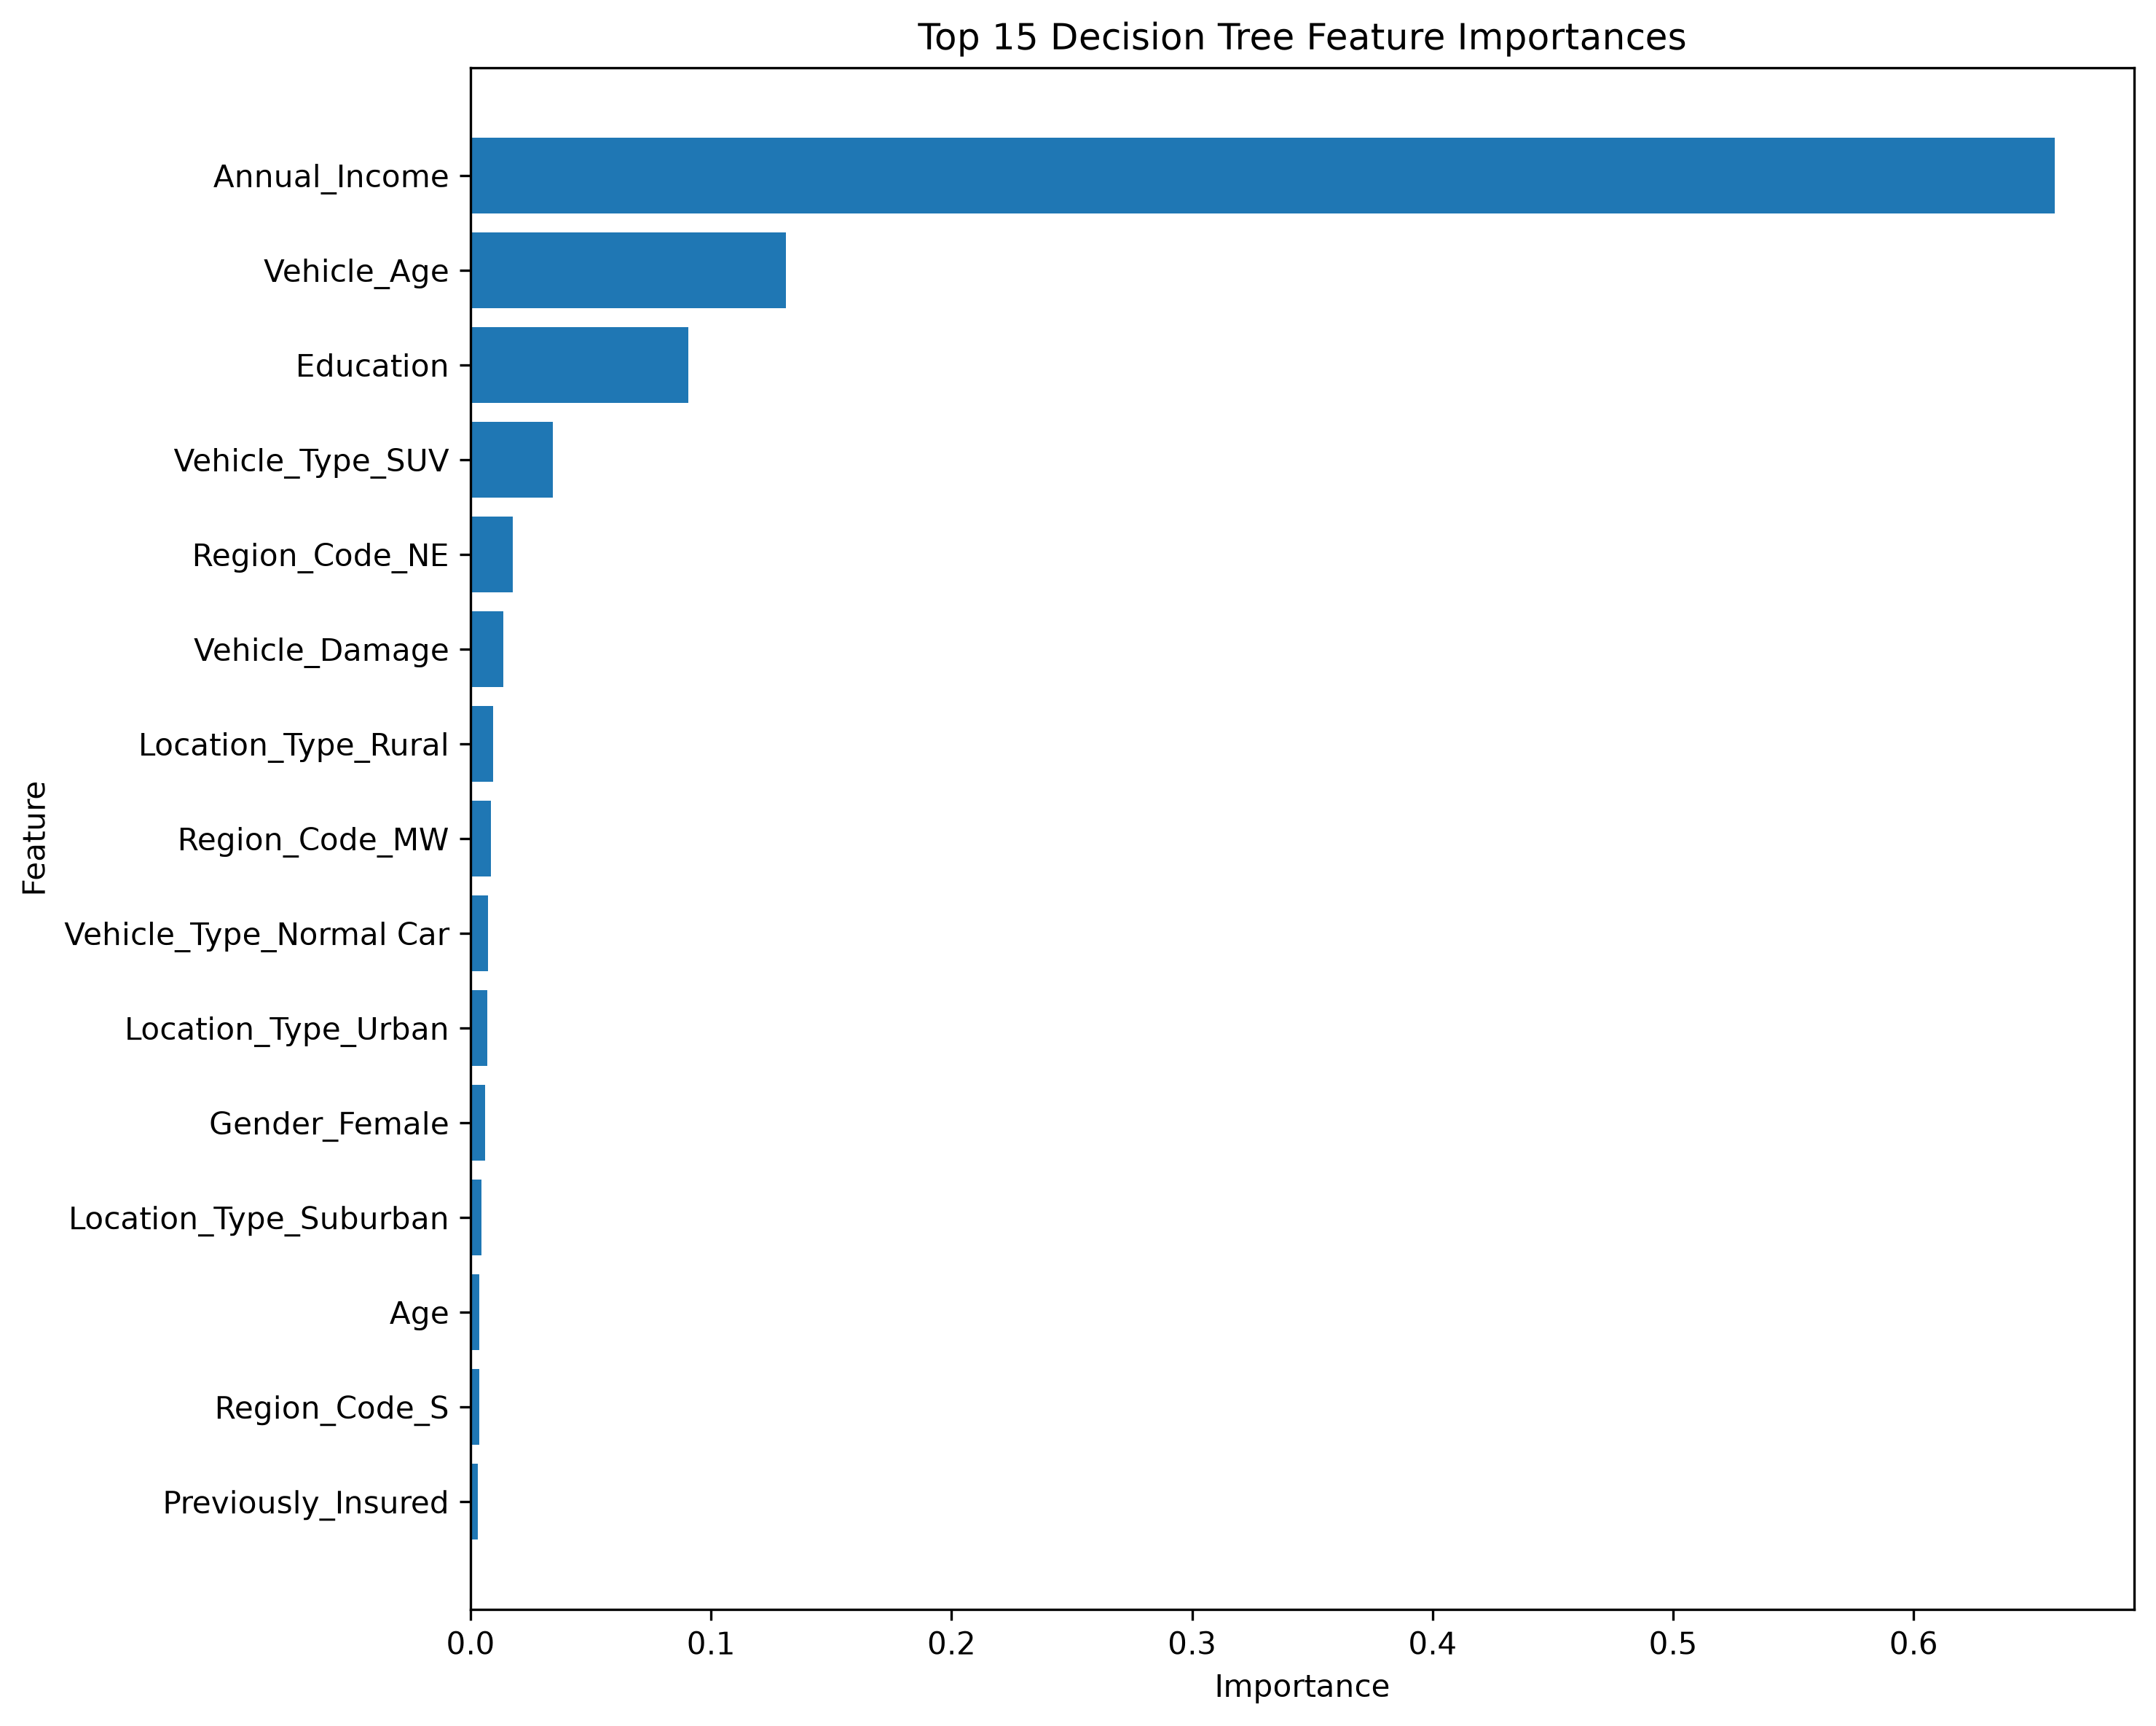

In [27]:
plt.figure(figsize=(10, 8))

plt.barh(
    top_dt_features['Feature'],
    top_dt_features['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 15 Decision Tree Feature Importances')

plt.gca().invert_yaxis()
plt.tight_layout()

# Save
plt.savefig(
    'decision_tree_feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# Display
display(
    Image(filename='decision_tree_feature_importance.png')
)

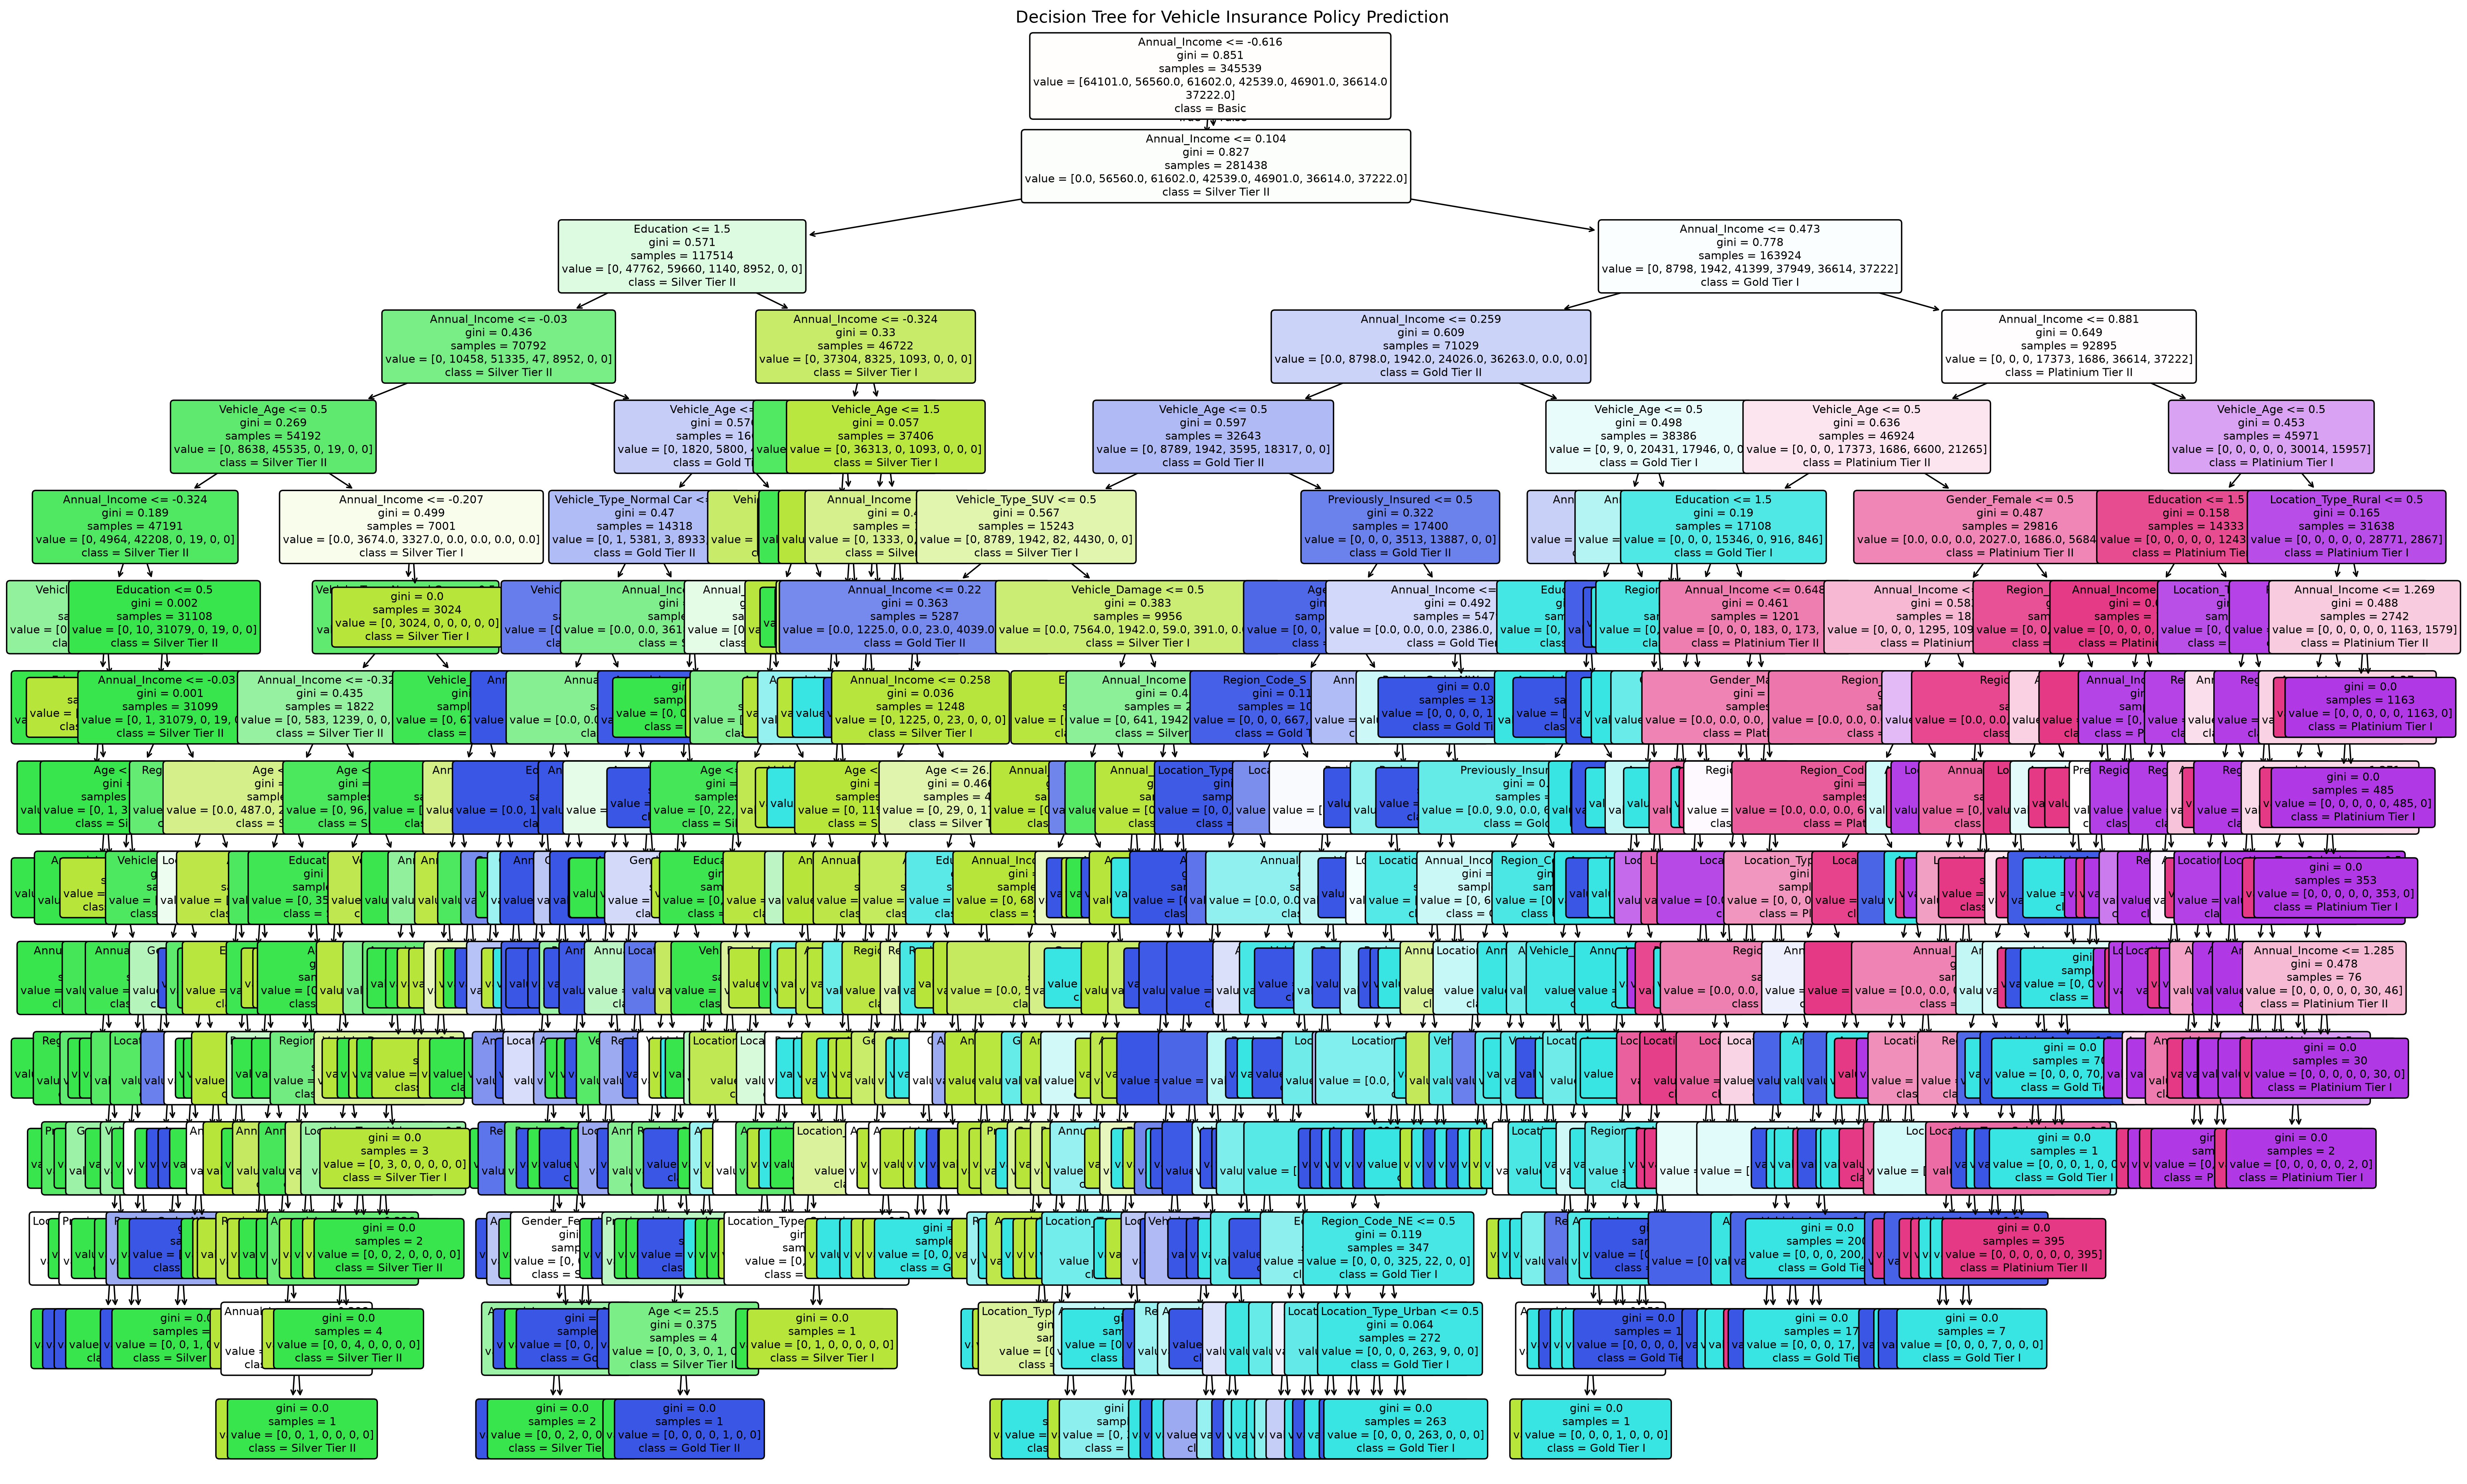

In [28]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.figure(figsize=(25, 15))

plot_tree(
    dt_model,
    feature_names=X_train.columns,
    class_names=policy_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title('Decision Tree for Vehicle Insurance Policy Prediction')

plt.tight_layout()

# Save
plt.savefig(
    'decision_tree.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# Display
display(
    Image(filename='decision_tree.png')
)